# Student Exam Performance Predictor

**Assignment 1** - Python, NumPy, Pandas, Matplotlib and scikit-learn

In this project I look at whether the number of hours a student studies is linked to the
score they get in the exam. Using the 13 records given in the assignment, I explore the
data, plot it, and train a Linear Regression model that predicts an exam score from study hours.

## 1. Project definition and SDLC plan

### Project requirements

The Academic Support Office would like a simple tool that tells them whether studying longer
goes together with better exam results. The tool takes study hours and exam scores for 13
students as its input. It should produce basic statistics, a clean data table, a scatter plot
with a regression line, and a comparison of predicted and actual scores. Finally, it should be
able to estimate the score of a student from their study hours, such as 7.5 hours, and say how
far that estimate can be trusted.

### SDLC plan

| SDLC stage | Application to this project |
|---|---|
| Requirements | Find out if study hours and exam scores are related, estimate a score from a given number of hours, and report how accurate and limited the estimate is. |
| Design | Put the data into NumPy arrays, turn it into a Pandas table, look at it and plot it, split it into training and test parts, fit a line, measure the error, and write up the findings. |
| Implementation | NumPy handles the arrays and statistics, Pandas handles the table and filtering, Matplotlib draws the plots, and scikit-learn does the split, the regression, and the MAE. |
| Testing | Make sure the NumPy and Pandas numbers match, check that no student appears in both the training and test sets, use MAE to compare predictions with real scores, and rerun the full notebook from a fresh kernel. |
| Improvement | Gather data from many more students, add extra inputs like attendance, earlier grades, assignment marks and sleep, and check the model on students it has never seen. |

### Project flow

Raw data → NumPy arrays and statistics → Pandas table and filtering → scatter plot →
train/test split → Linear Regression → predictions and fitted line → MAE → conclusion

## 2. Numerical data setup and basic statistics

The two arrays line up, so the first value in each belongs to the first student, and so on.

In [1]:
import numpy as np

# Supplied project data: position i in both arrays is the same student
study_hours = np.array([1.0, 2.0, 2.5, 3.0, 4.0, 4.5, 5.0, 6.0, 6.5, 7.0, 8.0, 9.0, 10.0])
exam_scores = np.array([42, 48, 51, 55, 62, 65, 69, 75, 78, 82, 87, 91, 95])

print("Study-hour observations:", len(study_hours))
print("Exam-score observations:", len(exam_scores))

Study-hour observations: 13
Exam-score observations: 13


In [2]:
# Numerical profile of the dataset
print("Number of observations:", len(exam_scores))
print(f"Average study hours: {np.mean(study_hours):.2f}")
print(f"Average exam score: {np.mean(exam_scores):.2f}")
print("Minimum exam score:", np.min(exam_scores))
print("Maximum exam score:", np.max(exam_scores))
print(f"Standard deviation of exam scores: {np.std(exam_scores):.2f}")

Number of observations: 13
Average study hours: 5.27
Average exam score: 69.23
Minimum exam score: 42
Maximum exam score: 95
Standard deviation of exam scores: 16.47


In [3]:
# Vectorized comparison: one True/False value per student
above_average = exam_scores > np.mean(exam_scores)
print("Above-average mask:", above_average)
print("Students scoring above the mean:", above_average.sum())

Above-average mask: [False False False False False False False  True  True  True  True  True
  True]
Students scoring above the mean: 6


The expression `exam_scores > np.mean(exam_scores)` checks every score against the average
at once and gives back an array of `True`/`False` values, one for each student. A `True`
means that student beat the average. Since Python treats `True` as 1 and `False` as 0,
adding up the array with `.sum()` tells us how many students were above average, with no
need to count by hand.

**What the statistics show:** On average the students studied 5.27 hours and scored 69.23.
The lowest score was 42 and the highest was 95, with a standard deviation of 16.47 points.
Six of the 13 students were above the average, and the scores clearly climb as study hours go up.

## 3. Structured dataset and data inspection

In [4]:
import pandas as pd

df = pd.DataFrame({"StudyHours": study_hours, "ExamScore": exam_scores})
print("Print the top 5 values of the data set")
df.head()

Print the top 5 values of the data set


,StudyHours,ExamScore
0,1.0,42
1,2.0,48
2,2.5,51
3,3.0,55
4,4.0,62


In [5]:
print("Printing the shape of the data set")
df.shape

Printing the shape of the data set


(13, 2)

In [6]:
print("Printing the description about the data set")
df.describe()

Printing the description about the data set


,StudyHours,ExamScore
count,13.000000,13.000000
mean,5.269231,69.230769
std,2.781002,17.137453
min,1.000000,42.000000
25%,3.000000,55.000000
50%,5.000000,69.000000
75%,7.000000,82.000000
max,10.000000,95.000000


- `df.head()` prints the first five rows, which lets me confirm each student's hours sit next
  to the right score.
- `df.shape` returns (13, 2), meaning 13 students and 2 columns.
- `df.describe()` lists the count, average, spread, smallest value, quartiles and largest value
  for both columns.

The averages, minimum and maximum are the same as the ones from NumPy. The standard deviation
is 17.14 here against 16.47 earlier which was printed earlier. This happens because Pandas divides by N−1 (sample
standard deviation), whereas `np.std` divides by N (population standard deviation) unless told
otherwise. The next cell shows the two match once NumPy uses `ddof=1`.

In [7]:
print(f"NumPy std with ddof=1: {np.std(exam_scores, ddof=1):.2f}")
print(f"Pandas std:            {df['ExamScore'].std():.2f}")

NumPy std with ddof=1: 17.14
Pandas std:            17.14


In [8]:
# New feature calculated from the data, not typed by hand
df["AboveAverage"] = df["ExamScore"] > df["ExamScore"].mean()
df

,StudyHours,ExamScore,AboveAverage
0,1.0,42,False
1,2.0,48,False
2,2.5,51,False
3,3.0,55,False
4,4.0,62,False
5,4.5,65,False
6,5.0,69,False
7,6.0,75,True
8,6.5,78,True
9,7.0,82,True


In [9]:
# Stakeholder query: at least 6 study hours AND at least 75 points
df[(df["StudyHours"] >= 6) & (df["ExamScore"] >= 75)]

,StudyHours,ExamScore,AboveAverage
7,6.0,75,True
8,6.5,78,True
9,7.0,82,True
10,8.0,87,True
11,9.0,91,True
12,10.0,95,True


Six students meet both conditions: they studied for 6 hours or more and scored 75 or higher.

**Why Pandas helps here:** A NumPy array is just a list of numbers, which is great for maths
but has no labels. A DataFrame stores the data as a table with named columns, so every
student's hours, score and `AboveAverage` value stay together in one row. This makes it much
simpler to look at the data, add new columns and pick out rows that match a condition.

## 4. Exploratory visualization

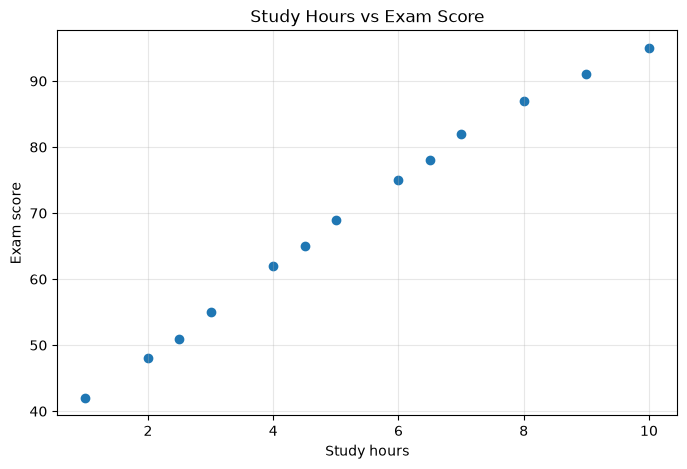

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(df["StudyHours"], df["ExamScore"])
plt.title("Study Hours vs Exam Score")
plt.xlabel("Study hours")
plt.ylabel("Exam score")
plt.grid(alpha=0.3)
plt.show()

### Pre-model observation

There is a clear and strong positive trend: the more hours a student studied, the higher
their score tended to be. The dots line up almost in a straight line and none of them stands
out as unusual, though the rise becomes a little gentler after roughly 8 hours. This only
tells us the two move together; it does not prove that extra study by itself causes better scores.

I come back to this plot in Stage 5 to add the regression line once the model has been trained.

## 5. Linear Regression model

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Double brackets keep X two-dimensional, as scikit-learn expects
X = df[["StudyHours"]]
y = df["ExamScore"]
print("X shape:", X.shape)
print("y shape:", y.shape)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training observations:", len(X_train))
print("Test observations:", len(X_test))

X shape: (13, 1)
y shape: (13,)
Training observations: 10
Test observations: 3


In [12]:
model = LinearRegression()
model.fit(X_train, y_train)

print(f"Coefficient: {model.coef_[0]:.2f}")
print(f"Intercept: {model.intercept_:.2f}")

Coefficient: 6.07
Intercept: 37.23


In [13]:
predictions = model.predict(X_test)

results = pd.DataFrame({"Actual": y_test, "Predicted": predictions.round(2)})
results

,Actual,Predicted
11,91,91.87
9,82,79.73
0,42,43.30


The trained model comes out as **predicted score = 37.23 + 6.07 × study hours**. For the three
test students, the predicted scores land within roughly 1 to 2 points of what they really got.

- **What is X and what is y?** `X` holds the study hours, which go into the model. `y` holds
  the exam scores, which are what the model tries to predict.
- **Why keep some data for testing?** The test students are hidden from the model while it
  learns. Checking its predictions on them shows whether it works on new data, not just on
  data it has already seen.
- **What does `model.fit()` learn?** It works out the slope (coefficient) and starting point
  (intercept) of the straight line that sits closest to the training points, by keeping the
  squared errors as small as possible.
- **What does `model.predict()` produce?** It takes study hours and returns the exam score
  that the fitted line gives for each one.
- **What does the coefficient mean?** Every extra hour of study goes with roughly 6.07 more
  points in the predicted score. The intercept (37.23) is where the line would be at 0 hours;
  no student in the data studied 0 hours, so it is not a realistic score for anyone.

### Stage 4 revisited: scatter plot with the fitted regression line

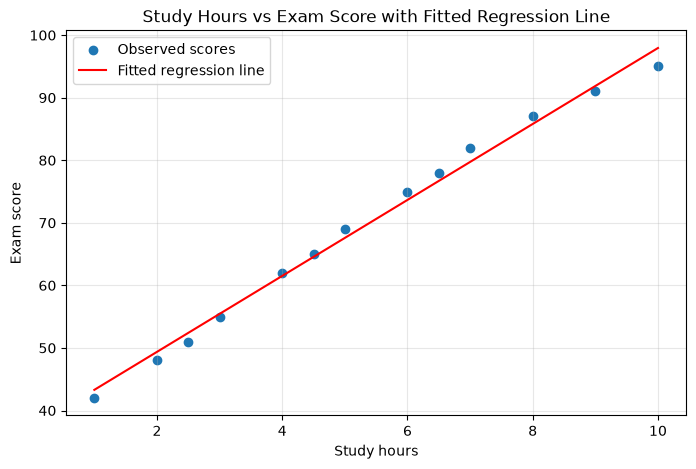

In [14]:
# Line drawn from the trained model's predictions across the observed range
line_hours = pd.DataFrame({"StudyHours": np.linspace(1, 10, 100)})

plt.figure(figsize=(8, 5))
plt.scatter(df["StudyHours"], df["ExamScore"], label="Observed scores")
plt.plot(line_hours["StudyHours"], model.predict(line_hours), color="red", label="Fitted regression line")
plt.title("Study Hours vs Exam Score with Fitted Regression Line")
plt.xlabel("Study hours")
plt.ylabel("Exam score")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

On its own, the scatter plot only shows individual students. The red line turns the overall
pattern into one simple rule, so I can read off an expected score for any number of hours
between 1 and 10, for example 7.5. The distance from each dot up or down to the line also shows
how much the model misses that student's real score. In this case the dots stay close to the line.

## 6. Model evaluation and practical prediction

In [15]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(y_test, predictions)
print(f"Mean Absolute Error (MAE): {mae:.2f} points")

Mean Absolute Error (MAE): 1.48 points


An MAE of 1.48 tells us that, for the three test students, the model's guess was wrong by
about one and a half exam points on average. The unit is exam points, not percent. Because the
test set has just three students, this is only a rough check and cannot prove how well the model
would do for a wider group of students.

In [16]:
prediction_7_5 = model.predict(pd.DataFrame({"StudyHours": [7.5]}))[0]
print(f"Predicted score for 7.5 study hours: {prediction_7_5:.2f}")

Predicted score for 7.5 study hours: 82.77


In [17]:
prediction_100 = model.predict(pd.DataFrame({"StudyHours": [100]}))[0]
print(f"Predicted score for 100 study hours: {prediction_100:.2f}")

Predicted score for 100 study hours: 644.36


For 7.5 hours the model predicts about 82.77 points. Since 7.5 sits between the smallest (1)
and largest (10) study hours in the data, this is interpolation, and the estimate is sensible.

The 100-hour prediction is a different story and I would not rely on it. The data only covers
1 to 10 hours, so the model is simply stretching its straight line far beyond anything it has
seen, which is called extrapolation. It returns 644.36, a score that cannot exist. This shows
that a model will always give an answer, even when the answer makes no sense.

## 7. Final project conclusion and technical quality

### Final project conclusion

Looking at the data, study hours and exam scores rise together in a strong positive pattern.
The scatter plot is close to a straight line with no clear outliers, although scores level off
a little after about 8 hours. After training on 10 students, the Linear Regression model found
that each additional hour of study is linked to around 6.07 extra predicted points. The fitted
line runs close to the actual points, and the MAE on the 3 test students was only 1.48 points,
so the model describes this small dataset well.

The prediction of about 82.77 points for 7.5 hours shows the prototype doing its main job:
turning a new number of study hours into an expected score. It is sensible because 7.5 hours
falls inside the 1–10 hour range of the data, whereas 100 hours gives an impossible 644.36 points.

There are several limitations. The dataset contains only 13 students and the test set only 3,
study hours are the sole input, and the results show a link rather than cause and effect.
Self-reported study hours may also be inaccurate. A better future version would use a larger,
more varied group of students and include attendance, previous grades, assignment marks, sleep
and course difficulty. For now, the tool demonstrates the method but should not be used for
decisions about individual students.

### Technical checks

In [18]:
assert len(study_hours) == len(exam_scores) == len(df)
assert set(X_train.index).isdisjoint(X_test.index), "Training and test sets must not overlap"
assert len(predictions) == len(y_test)
print("All checks passed.")

All checks passed.


### Library roles

| Library | Role in this project |
|---|---|
| NumPy | Keeps the hours and scores as numeric arrays, works out the statistics, and does the above-average comparison in one step. |
| Pandas | Organises the data into a labeled table, lets me inspect it, adds the `AboveAverage` column, and filters rows for the Academic Support Office's question. |
| Matplotlib | Draws the first scatter plot and then the same plot with the regression line. |
| scikit-learn | Splits the data into training and test sets, trains the Linear Regression model, makes predictions, and calculates MAE. |